## 04-Classification Metrics: homework

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score, recall_score, precision_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
 

In [2]:
data = pd.read_csv("course_lead_scoring_2026.csv")

In [3]:
data.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
# imputing missing values
categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = ["annual_income", "number_of_courses_viewed", 
             "interaction_count", "lead_score"]

for col in data.columns:
    data[[col]] = data[[col]].fillna('NA' if col in categorical else 0.0)

In [32]:
# train test split
df_full_train, df_test = train_test_split(data, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_train = df_train["converted"].copy()
df_train = df_train.drop(columns = "converted")

y_val = df_val["converted"].copy()
df_val = df_val.drop(columns = "converted")

y_test = df_test["converted"].copy()
df_test = df_test.drop(columns = "converted")

## Question 1: ROC AUC feature importance

In [34]:
def compute_auc(variable):
    result = roc_auc_score(y_train, df_train[variable])
    if result < .5:
        result = roc_auc_score(y_train, -df_train[variable])
    return round(result,2)

results = []
for var in numerical:
    results.append({"variable": var, "AUC": compute_auc(var)})
    
pd.DataFrame(results)


,variable,AUC
0,annual_income,0.61
1,number_of_courses_viewed,0.72
2,interaction_count,0.76
3,lead_score,0.79


### Question 2. Logistic regression AUC

In [35]:
### OHE for categorical variables
dv = DictVectorizer(sparse = False)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))


def onehot_encode(df):
    return dv.transform(df.to_dict(orient='records'))

X_val = onehot_encode(df_val)
X_test = onehot_encode(df_test)

In [36]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [42]:
val_pred_proba = model.predict_proba(X_val)[:, 1]

print("AUC score for logistic regression:", round(roc_auc_score(y_val, val_pred_proba),3))

AUC score for logistic regression: 0.732


In [41]:
val_pred_proba

array([[0.45527705, 0.54472295],
       [0.20994809, 0.79005191],
       [0.49022118, 0.50977882],
       ...,
       [0.24221397, 0.75778603],
       [0.22098619, 0.77901381],
       [0.59553457, 0.40446543]], shape=(1000, 2))

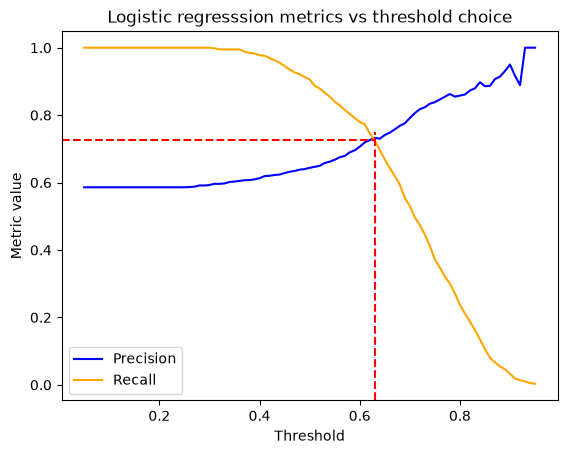

In [74]:
def calculate_metrics(thr):
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    val_pred = (model.predict_proba(X_val)[:, 1] > thr).astype(float)
    return {"threshold":thr, "recall": recall_score(y_val, val_pred), "precision": precision_score(y_val, val_pred)}

results = pd.DataFrame([calculate_metrics(thr) for thr in np.arange(0.05 , .96, .01)])
results["abs_diff"] = np.abs(results.precision - results.recall)

best_thr = results.loc[results["abs_diff"] == results.abs_diff.min(), "threshold"].values[0]
value = results.loc[results["abs_diff"] == results.abs_diff.min(), "recall"].values[0]



plt.plot(results.threshold, results.precision, color = "blue", label = "Precision")
plt.plot(results.threshold, results.recall, color = "orange", label = "Recall")
plt.axvline(x = best_thr, ymin = 0, ymax = value, color = "red", linestyle = "dashed")
plt.axhline(y = value, xmin = 0, xmax = best_thr, color = "red", linestyle = "dashed")
plt.xlabel("Threshold")
plt.legend()
plt.title("Logistic regresssion metrics vs threshold choice")
plt.ylabel("Metric value")
plt.show()
    

### Question 4. F1-score

In [76]:
results["f1"] = 2 / (1/ results.precision + 1/results.recall)

In [77]:
print("Threshold to maximize f1-score:", round(results.loc[results.f1 == results.f1.max(), "threshold"].values[0],2))

Threshold to maximize f1-score: 0.41


In [96]:
def validation_auc(c=1.0):
    kf = KFold(n_splits=5, shuffle=True, random_state=1)
    fold_results = []
    for i, (train_idx, val_idx) in enumerate(kf.split(df_full_train)):

        df_fold_train = df_full_train.iloc[train_idx, :]
        df_fold_test = df_full_train.iloc[val_idx, :]

        y_fold_train = df_fold_train.converted
        y_fold_test = df_fold_test.converted
        df_fold_train = df_fold_train.drop(columns = "converted")
        df_fold_test = df_fold_test.drop(columns = "converted")

        X_fold_train =  dv.transform(df_fold_train.to_dict(orient='records'))
        X_fold_test = dv.transform(df_fold_test.to_dict(orient='records'))
 
        model = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
        model.fit(X_fold_train, y_fold_train)
        fold_pred_proba = model.predict_proba(X_fold_test)[:, 1]
        fold_results.append(roc_auc_score(y_fold_test, fold_pred_proba))

    return np.mean(fold_results), np.std(fold_results)

print("The mean 5-CV AUC is: {0:.3f}, whereas its SD is: {1:.3f}".format(*validation_auc()) )

The mean 5-CV AUC is: 0.732, whereas its SD is: 0.007


### Question 5

In [104]:
results = pd.DataFrame([(c, *validation_auc(c)) for c in [0.000001, 0.001, 1]], columns = ["C", "Mean AUC", "AUC std. dev."])
results.loc[:, ["Mean AUC", "AUC std. dev."]] = results.loc[:, ["Mean AUC", "AUC std. dev."]].apply(lambda x: round(x,3))
results

,C,Mean AUC,AUC std. dev.
0,0.000001,0.617,0.019
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007
